# CartPole, Q-learning and A2C, from zero

**How this notebook works.** Every piece is built small, then run, then explained. Before we touch the real CartPole game we build a **made-up dummy game** so you can see each idea with tiny numbers you can check by hand. After each dummy piece, we move it over to the real CartPole code and I point out which line matches which.

Rules I'm following:
- No word is used before it is explained. If you hit a word I never explained, that's my mistake.
- Every code cell prints what it is doing, so you can read the output like a log.
- Results use random numbers, so if you re-run a cell your numbers will differ a little. The patterns stay the same.

**Roadmap**
1. A game is just a loop
2. A policy is a rule, and we can measure rules
3. Q-learning on the dummy game (a table of scores you keep correcting)
4. The real CartPole game
5. Buckets: making CartPole fit in a table
6. Q-learning on real CartPole
7. Actor-critic on the dummy game (the idea behind A2C)
8. Actor-critic on real CartPole
9. Where neural networks come in
10. Glossary

# Part 1: A game is just a loop

Every game we'll use has the same four ingredients:

| Ingredient | Meaning | In our dummy game |
|---|---|---|
| **state** | what you can see right now | one number called `tilt` |
| **action** | what you can do | push left (`0`) or push right (`1`) |
| **reward** | points you get for the step you just took | +1 for every tick you're still standing |
| **done** | whether the game is over | you fell over, or time ran out |

The dummy game: you balance something. Each tick the world shoves the tilt by -1 or +1 at random, and then you push it by -1 (left) or +1 (right). New tilt = old tilt + world's shove + your push. If the tilt reaches +3 or -3 you fall over. If you survive 50 ticks, the game stops (you win).

Real games usually report *two* kinds of "over", so the dummy does too:
- `terminated` = the game ended because you failed (fell over)
- `truncated` = the game ended because time ran out (not your fault)

In [1]:
import random
import numpy as np

random.seed(5)
np.random.seed(1)

class DummyGame:
    # A made-up game, just to show the shape every game has.

    def __init__(self):
        self.tilt = 0
        self.ticks = 0
        self.last_drift = 0

    def reset(self):
        self.tilt = 0
        self.ticks = 0
        return self.tilt                        # hand back the starting state

    def step(self, action):                     # action: 0 = push left, 1 = push right
        drift = random.choice([-1, 1])          # the world shoves the tilt randomly
        push = -1 if action == 0 else +1        # your push
        self.last_drift = drift                 # (saved only so we can print it)
        self.tilt = self.tilt + drift + push    # new tilt = old tilt + shove + your push
        self.ticks = self.ticks + 1

        reward = 1                              # +1 for every tick we are still standing
        terminated = abs(self.tilt) >= 3        # True if we fell over
        truncated = self.ticks >= 50            # True if time ran out
        return self.tilt, reward, terminated, truncated

print("DummyGame defined.")

DummyGame defined.


Now the loop. Read the printed lines as sentences: *"tilt was X, I pushed Y, world shoved Z, so tilt is now X+Y+Z."* The player here is a coin flip. It ignores the state completely.

In [2]:
game = DummyGame()
state = game.reset()
print("start: state =", state)
print()

done = False
tick = 0
total_reward = 0
while not done:
    action = random.choice([0, 1])              # the "player": a coin flip for now
    old_state = state
    state, reward, terminated, truncated = game.step(action)
    done = terminated or truncated
    tick = tick + 1
    total_reward = total_reward + reward
    push = -1 if action == 0 else +1
    print(f"tick {tick}: tilt was {old_state:+d}, I pushed {push:+d}, world shoved {game.last_drift:+d}"
          f"  ->  tilt is now {state:+d}   (reward {reward}, fell={terminated}, timeout={truncated})")

print()
print("game over. total reward =", total_reward)

start: state = 0

tick 1: tilt was +0, I pushed +1, world shoved +1  ->  tilt is now +2   (reward 1, fell=False, timeout=False)
tick 2: tilt was +2, I pushed -1, world shoved +1  ->  tilt is now +2   (reward 1, fell=False, timeout=False)
tick 3: tilt was +2, I pushed -1, world shoved -1  ->  tilt is now +0   (reward 1, fell=False, timeout=False)
tick 4: tilt was +0, I pushed -1, world shoved -1  ->  tilt is now -2   (reward 1, fell=False, timeout=False)
tick 5: tilt was -2, I pushed +1, world shoved +1  ->  tilt is now +0   (reward 1, fell=False, timeout=False)
tick 6: tilt was +0, I pushed -1, world shoved +1  ->  tilt is now +0   (reward 1, fell=False, timeout=False)
tick 7: tilt was +0, I pushed -1, world shoved -1  ->  tilt is now -2   (reward 1, fell=False, timeout=False)
tick 8: tilt was -2, I pushed -1, world shoved -1  ->  tilt is now -4   (reward 1, fell=True, timeout=False)

game over. total reward = 8


**What each variable held, in that loop**

- `state` — the current tilt. It is replaced by the new tilt after every step.
- `action` — 0 or 1, what we chose this tick.
- `reward` — always 1 here. `total_reward` adds them up, so it equals "how many ticks I survived".
- `terminated` / `truncated` — `done` becomes True when either is True, and the `while` loop stops.

**Where this goes in real CartPole:** the loop is identical. `game.reset()` becomes `env.reset()`, `game.step(action)` becomes `env.step(action)`, and `state` becomes four numbers instead of one. The only line we will keep changing for the rest of the notebook is this one:

```python
action = random.choice([0, 1])      # <-- all of "learning" is about replacing this line
```

# Part 2: A policy is a rule, and we can measure rules

A **policy** is any function that takes a state and returns an action. That's all the word means. Below are two policies for the dummy game:

- `coin_flip_policy` ignores the state.
- `lean_rule_policy` is a rule I wrote by hand: *if the tilt is positive, push left. Otherwise push right.*

To compare policies we need a number. We'll play many games and average the total reward. First a function that plays exactly one game with whatever policy you hand it.

In [3]:
def coin_flip_policy(state):
    return random.choice([0, 1])

def lean_rule_policy(state):
    # A hand-written rule: if tilt is positive, push left (0). Otherwise push right (1).
    if state > 0:
        return 0
    else:
        return 1

def play_one_game(policy):
    game = DummyGame()
    state = game.reset()
    total = 0
    while True:
        action = policy(state)                  # <-- the policy plugs in right here
        state, reward, terminated, truncated = game.step(action)
        total = total + reward
        if terminated or truncated:
            return total

print("10 games with the coin flip:", [play_one_game(coin_flip_policy) for _ in range(10)])
print("10 games with the lean rule:", [play_one_game(lean_rule_policy) for _ in range(10)])

10 games with the coin flip: [6, 2, 12, 7, 3, 3, 8, 4, 16, 7]
10 games with the lean rule: [50, 50, 50, 50, 50, 50, 50, 50, 50, 50]


In [4]:
coin_scores = [play_one_game(coin_flip_policy) for _ in range(1000)]
rule_scores = [play_one_game(lean_rule_policy) for _ in range(1000)]

print("coin flip, average over 1000 games:", sum(coin_scores) / len(coin_scores))
print("lean rule, average over 1000 games:", sum(rule_scores) / len(rule_scores))
print("(50 is the maximum, because the game stops at 50 ticks)")

coin flip, average over 1000 games: 8.171
lean rule, average over 1000 games: 50.0
(50 is the maximum, because the game stops at 50 ticks)


The hand-written rule is much better. Why does it work? Tilt values in this game are always even (-2, 0, 2 while alive). From tilt 2, pushing left can never reach 3; from tilt -2, pushing right can never reach -3. The rule always pushes *toward* zero.

**This is what learning is for.** I wrote that rule by looking at the game and thinking. For real CartPole, and for harder games, nobody can write the rule by hand. **Learning** means: *find a good rule automatically by playing and keeping score.* Parts 3 to 9 are two different ways of doing that.

# Part 3: Q-learning on the dummy game

### The idea: a table of scores

Make a dictionary with one entry for every (state, action) pair. Each entry holds a number, called **Q**, that answers:

> *"If I'm in this state and take this action, and then play well afterwards, about how many points will I collect from here to the end?"*

The dummy game only has 3 alive states (-2, 0, 2) and 2 actions, so the table has 6 entries. It starts knowing nothing, so every entry is 0.

In [5]:
Q = {}
for s in [-2, 0, 2]:
    for a in [0, 1]:
        Q[(s, a)] = 0.0

for key in Q:
    print(f"Q[state={key[0]:+d}, action={key[1]}] = {Q[key]}")

Q[state=-2, action=0] = 0.0
Q[state=-2, action=1] = 0.0
Q[state=+0, action=0] = 0.0
Q[state=+0, action=1] = 0.0
Q[state=+2, action=0] = 0.0
Q[state=+2, action=1] = 0.0


### Using the table to act

In a state, look up Q for left and Q for right, and pick the bigger one. That is a policy built out of a table. Two details:

- **Ties** (like at the start, when everything is 0): pick randomly.
- **Exploring:** if you only ever pick the current best, you never try anything else, so you can never discover that something is better. So with a small probability `epsilon` (say 0.2 = 20% of ticks) we ignore the table and pick randomly.

In [6]:
def best_action(Q, state):
    q_left = Q[(state, 0)]
    q_right = Q[(state, 1)]
    if q_left > q_right:
        return 0
    if q_right > q_left:
        return 1
    return random.choice([0, 1])               # tie: pick randomly

print("With an all-zero table, best_action is a coin flip:", [best_action(Q, 2) for _ in range(10)])

With an all-zero table, best_action is a coin flip: [1, 0, 0, 1, 0, 1, 1, 0, 0, 0]


### "Updating Q" — watching the arithmetic once with pretend numbers

"Update" means: **overwrite one table entry with a slightly better guess.** Here is how the better guess is made.

Suppose you were in state **A**, pushed **right**, got **reward 1**, and landed in state **B**.

1. Look at state B and find the best Q available there (the best of left/right).
2. Your improved estimate for `Q[A, right]` is called the **target**: `target = reward + gamma * (best Q at B)`
3. Don't jump all the way to the target (one step can be a fluke). Move a fraction `alpha` of the way: `new = old + alpha * (target - old)`

Two settings appear:
- `alpha` (the **learning rate**): how big a fraction to move. 0.1 = move 10% of the way.
- `gamma` (the **discount**): how much a point one step later is worth compared to a point now. 0.9 means "one step later counts 90%". It keeps the numbers from growing forever and makes sooner points matter more.

In [7]:
alpha = 0.1
gamma = 0.9

# PRETEND numbers, just to watch the arithmetic one time.
q_A_right = 6.0       # the current table entry we are about to fix
q_B_left  = 10.0      # best Q available in the next state B
q_B_right = 7.0
reward = 1

best_next = max(q_B_left, q_B_right)
target = reward + gamma * best_next
change = alpha * (target - q_A_right)
new_q_A_right = q_A_right + change

print(f"best Q available in B          = max({q_B_left}, {q_B_right}) = {best_next}")
print(f"target                         = reward + gamma * best_next = {reward} + {gamma} * {best_next} = {target}")
print(f"old Q[A, right]                = {q_A_right}")
print(f"gap between target and old     = {target} - {q_A_right} = {target - q_A_right}")
print(f"move {alpha} of the way         = {alpha} * {target - q_A_right} = {change:.2f}")
print(f"new Q[A, right]                = {q_A_right} + {change:.2f} = {new_q_A_right:.2f}")

best Q available in B          = max(10.0, 7.0) = 10.0
target                         = reward + gamma * best_next = 1 + 0.9 * 10.0 = 10.0
old Q[A, right]                = 6.0
gap between target and old     = 10.0 - 6.0 = 4.0
move 0.1 of the way         = 0.1 * 4.0 = 0.40
new Q[A, right]                = 6.0 + 0.40 = 6.40


### The real update, inside a loop, on the dummy game

Same arithmetic, but now the numbers come from actually playing. One special case: if the step made you **fall** (`terminated`), there is no "next state's best Q", because nothing comes after falling, so the future part is 0.

The first few updates are printed so you can check them against the formula.

In [8]:
def train_q_dummy(num_games, epsilon, alpha, gamma, show_first_updates=0):
    Q = {}
    for s in [-2, 0, 2]:
        for a in [0, 1]:
            Q[(s, a)] = 0.0

    shown = 0
    for g in range(num_games):
        game = DummyGame()
        state = game.reset()
        while True:
            # pick an action: explore sometimes, otherwise trust the table
            if random.random() < epsilon:
                action = random.choice([0, 1])
            else:
                action = best_action(Q, state)

            next_state, reward, terminated, truncated = game.step(action)

            # the better guess ("target")
            if terminated:
                future = 0.0                    # fell: nothing comes after
            else:
                future = max(Q[(next_state, 0)], Q[(next_state, 1)])
            target = reward + gamma * future

            # the update: move a fraction alpha of the way toward the target
            old = Q[(state, action)]
            new = old + alpha * (target - old)
            Q[(state, action)] = new

            if shown < show_first_updates:
                print(f"state {state:+d}, action {action}, reward {reward}, next state {next_state:+d}"
                      f" | future {future:.3f}, target {target:.3f} | Q: {old:.3f} -> {new:.3f}")
                shown += 1

            state = next_state
            if terminated or truncated:
                break
    return Q

print("The first 8 updates of a brand new table:")
_ = train_q_dummy(num_games=1, epsilon=0.2, alpha=0.1, gamma=0.9, show_first_updates=8)

The first 8 updates of a brand new table:
state +0, action 1, reward 1, next state +0 | future 0.000, target 1.000 | Q: 0.000 -> 0.100
state +0, action 1, reward 1, next state +2 | future 0.000, target 1.000 | Q: 0.100 -> 0.190
state +2, action 1, reward 1, next state +2 | future 0.000, target 1.000 | Q: 0.000 -> 0.100
state +2, action 1, reward 1, next state +2 | future 0.100, target 1.090 | Q: 0.100 -> 0.199
state +2, action 1, reward 1, next state +2 | future 0.199, target 1.179 | Q: 0.199 -> 0.297
state +2, action 0, reward 1, next state +0 | future 0.190, target 1.171 | Q: 0.000 -> 0.117
state +0, action 1, reward 1, next state +2 | future 0.297, target 1.267 | Q: 0.190 -> 0.298
state +2, action 1, reward 1, next state +2 | future 0.297, target 1.267 | Q: 0.297 -> 0.394


Notice that early on most targets are just `1.0`, because the table is all zeros, so "best Q next" is 0. As games go on, the numbers in the table grow and the information spreads **backward**: a state next to a fall learns it's bad, then the state before *that* learns it leads to a bad state, and so on. Now let it play 3000 games.

In [9]:
Q = train_q_dummy(num_games=3000, epsilon=0.2, alpha=0.1, gamma=0.9)

print("Learned table:")
for s in [-2, 0, 2]:
    print(f"  state {s:+d}:  Q(push left) = {Q[(s,0)]:6.2f}    Q(push right) = {Q[(s,1)]:6.2f}")

print()
print("What the table says to do (the policy it implies):")
for s in [-2, 0, 2]:
    choice = "push LEFT" if Q[(s,0)] > Q[(s,1)] else "push RIGHT"
    print(f"  state {s:+d}: {choice}")

Learned table:
  state -2:  Q(push left) =   5.72    Q(push right) =  10.00
  state +0:  Q(push left) =  10.00    Q(push right) =  10.00
  state +2:  Q(push left) =  10.00    Q(push right) =   4.48

What the table says to do (the policy it implies):
  state -2: push RIGHT
  state +0: push RIGHT
  state +2: push LEFT


In [10]:
def q_table_policy(state):
    return best_action(Q, state)                # no exploring when we are just playing

learned = [play_one_game(q_table_policy) for _ in range(1000)]

print("coin flip      :", sum(coin_scores) / 1000)
print("hand-made rule :", sum(rule_scores) / 1000)
print("learned table  :", sum(learned) / 1000)

coin flip      : 8.171
hand-made rule : 50.0
learned table  : 50.0


**What to notice**

- At tilt +2 the table prefers pushing left, and at tilt -2 it prefers pushing right. That's the same rule I wrote by hand, found automatically from nothing but "+1 per tick" and falling.
- At tilt 0 the two Q values are close, because by symmetry neither choice is dangerous right away. The table can pick either.

**Where this goes in real CartPole:** the code is the same shape. Two things change: (1) the state is four decimal numbers, which can't be dictionary keys because there are infinitely many, and (2) I use `gamma = 0.99` instead of 0.9 because CartPole needs foresight over hundreds of ticks. Part 5 handles (1). First, let's meet the real game.

# Part 4: The real CartPole game

A cart on a track with a pole balanced on top. Each tick you push the cart left (`0`) or right (`1`). The state is **four numbers**:

| Index | Meaning | Rough range |
|---|---|---|
| `obs[0]` | cart position (0 = center) | -2.4 to 2.4 (past that = off the track) |
| `obs[1]` | cart velocity (how fast it moves) | about -2 to 2 |
| `obs[2]` | pole angle in radians (0 = straight up) | -0.21 to 0.21 (about ±12°; past that = fell) |
| `obs[3]` | pole angular velocity (how fast it's tipping) | about -3 to 3 |

Reward is +1 per tick. The game ends (`terminated`) when the pole or cart goes out of range, or (`truncated`) after 500 ticks. So **500 is a perfect score**. Note that real `env.step` returns *five* things; the last one, `info`, is extra data we ignore.

In [11]:
import gymnasium as gym

env = gym.make("CartPole-v1")
obs, info = env.reset(seed=0)

print("action choices:", env.action_space, "  (0 = push left, 1 = push right)")
print()
names = ["cart position", "cart velocity", "pole angle", "pole angular velocity"]
for i in range(4):
    print(f"obs[{i}] {names[i]:22s} = {obs[i]:+.4f}")

action choices: Discrete(2)   (0 = push left, 1 = push right)

obs[0] cart position          = +0.0137
obs[1] cart velocity          = -0.0230
obs[2] pole angle             = -0.0459
obs[3] pole angular velocity  = -0.0483


Now push right five times in a row and watch the four numbers change. Every line is one tick.

In [12]:
obs, info = env.reset()
print("start:", np.round(obs, 4))
for tick in range(1, 6):
    obs, reward, terminated, truncated, info = env.step(1)      # push right
    print(f"tick {tick}: pushed right -> state {np.round(obs, 4)}  reward {reward}  terminated {terminated}")

start: [0.0313 0.0413 0.0107 0.0229]
tick 1: pushed right -> state [ 0.0322  0.2362  0.0111 -0.2663]  reward 1.0  terminated False
tick 2: pushed right -> state [ 0.0369  0.4312  0.0058 -0.5555]  reward 1.0  terminated False
tick 3: pushed right -> state [ 0.0455  0.6262 -0.0053 -0.8464]  reward 1.0  terminated False
tick 4: pushed right -> state [ 0.058   0.8214 -0.0222 -1.1407]  reward 1.0  terminated False
tick 5: pushed right -> state [ 0.0745  1.0168 -0.0451 -1.4403]  reward 1.0  terminated False


The cart accelerates right (position and velocity go up), and the pole tips *backwards* (angle goes negative) because the base moved out from under it. Keep pushing the same way and it will fall within a few dozen ticks.

Let's measure two policies on the real game with the same kind of function as Part 2. The first is a coin flip. The second is a hand-written rule: *"if the pole is leaning right (angle > 0), push right to get under it; otherwise push left."* A third rule also looks at how fast the pole is tipping.

In [13]:
def evaluate_cartpole(policy, num_games=100):
    scores = []
    for _ in range(num_games):
        obs, info = env.reset()
        total = 0
        while True:
            action = policy(obs)                # <-- same plug-in point as before
            obs, reward, terminated, truncated, info = env.step(action)
            total = total + reward
            if terminated or truncated:
                break
        scores.append(total)
    return np.mean(scores), np.max(scores)

def cartpole_coin_flip(obs):
    return random.choice([0, 1])

def cartpole_lean_rule(obs):
    angle = obs[2]
    return 1 if angle > 0 else 0

def cartpole_lean_and_speed_rule(obs):
    angle = obs[2]
    angle_speed = obs[3]
    return 1 if (angle + angle_speed) > 0 else 0

for name, pol in [("coin flip", cartpole_coin_flip),
                  ("lean rule (angle only)", cartpole_lean_rule),
                  ("lean + tipping speed rule", cartpole_lean_and_speed_rule)]:
    avg, best = evaluate_cartpole(pol, 100)
    print(f"{name:28s} average score {avg:6.1f}   best game {best:.0f}   (max possible 500)")

coin flip                    average score   21.2   best game 58   (max possible 500)
lean rule (angle only)       average score   42.4   best game 64   (max possible 500)
lean + tipping speed rule    average score  490.2   best game 500   (max possible 500)


Using the pole's tipping *speed* as well as its angle helps a lot. The right rule depends on combining the four numbers in the right way, and finding that automatically is what Q-learning and A2C do.

**Mapping from the dummy game:**

| Dummy game | Real CartPole |
|---|---|
| `tilt` (1 number) | 4 numbers in `obs` |
| `game.step(action)` returns 4 things | `env.step(action)` returns 5 (extra `info` ignored) |
| `terminated`: tilt reached ±3 | `terminated`: pole too tilted or cart off the track |
| `truncated`: 50 ticks | `truncated`: 500 ticks |
| `play_one_game(policy)` | `evaluate_cartpole(policy)` |

# Part 5: Buckets — making CartPole fit in a table

The dummy game had 3 states, so a dictionary worked. CartPole's states are decimals like `0.0213`, so there are infinitely many, and a table can't have a row for each.

**Fix: bucketing.** Chop each number's range into a few intervals, and say which interval it's in. `np.digitize(x, edges)` does that: given a list of cut points (`edges`), it returns which interval `x` falls into (0 for left of the first edge, 1 for between the first and second, and so on). A demo with made-up cut points first:

In [14]:
edges_demo = np.array([-0.1, 0.0, 0.1])         # 3 cut points -> 4 buckets (0, 1, 2, 3)

for x in [-0.5, -0.05, 0.03, 0.2]:
    print(f"x = {x:+.2f}  -> bucket {int(np.digitize(x, edges_demo))}")

x = -0.50  -> bucket 0
x = -0.05  -> bucket 1
x = +0.03  -> bucket 2
x = +0.20  -> bucket 3


Now the real cut points, one list per each of the four numbers. I use more buckets for the pole angle and pole speed (they matter most) and fewer for cart position and velocity. A **state** in our table is now a *tuple of four bucket numbers*, like `(2, 2, 4, 3)`.

In [15]:
edges = [
    np.array([-1.2, -0.4, 0.4, 1.2]),               # cart position   -> 5 buckets
    np.array([-1.0, -0.3, 0.3, 1.0]),               # cart velocity   -> 5 buckets
    np.linspace(-0.21, 0.21, 9)[1:-1],              # pole angle      -> 8 buckets
    np.linspace(-2.0, 2.0, 9)[1:-1],                # pole ang. speed -> 8 buckets
]
bucket_counts = [len(e) + 1 for e in edges]

def to_bucket(obs):
    return tuple(int(np.digitize(obs[i], edges[i])) for i in range(4))

print("buckets per number:", bucket_counts)
print("total states in the table:", int(np.prod(bucket_counts)), "(5 * 5 * 8 * 8)")
print()

obs, info = env.reset()
for _ in range(3):
    print("real observation", np.round(obs, 3), " -> state (bucket numbers)", to_bucket(obs))
    obs, reward, terminated, truncated, info = env.step(random.choice([0, 1]))

buckets per number: [5, 5, 8, 8]
total states in the table: 1600 (5 * 5 * 8 * 8)

real observation [-0.044 -0.026  0.005  0.038]  -> state (bucket numbers) (2, 2, 4, 4)
real observation [-0.045 -0.221  0.005  0.332]  -> state (bucket numbers) (2, 2, 4, 4)
real observation [-0.049 -0.026  0.012  0.041]  -> state (bucket numbers) (2, 2, 4, 4)


The table is a numpy array with shape `(5, 5, 8, 8, 2)`: four bucket indexes pick a cell, and the last axis holds the two scores (left, right). Indexing it with a state tuple gives you that row of two numbers:

In [16]:
Q_demo = np.zeros(tuple(bucket_counts) + (2,))
print("table shape:", Q_demo.shape)

state = to_bucket(obs)
print("current state tuple:", state)
print("Q_demo[state] (scores for [left, right]):", Q_demo[state])
print("score for 'right' only:                  ", Q_demo[state + (1,)])

table shape: (5, 5, 8, 8, 2)
current state tuple: (2, 2, 4, 4)
Q_demo[state] (scores for [left, right]): [0. 0.]
score for 'right' only:                   0.0


# Part 6: Q-learning on real CartPole

This is the Part 3 code with three changes, and nothing else:

1. State = `to_bucket(obs)` instead of the raw tilt number.
2. Table = numpy array instead of dictionary.
3. `epsilon` starts at 1.0 (always random) and shrinks to 0.01 over the first 60% of games, so early on we explore and later we mostly trust the table.

Everything else, the target, the fraction-of-the-way update, the "fell means no future" rule, is the same.

In [17]:
def best_action_np(Q, state):
    row = Q[state]                              # the two scores for this state: [left, right]
    if row[0] == row[1]:
        return random.choice([0, 1])
    return int(np.argmax(row))

def train_q_cartpole(episodes, alpha=0.1, gamma=0.99):
    Q = np.zeros(tuple(bucket_counts) + (2,))
    scores = []
    for ep in range(episodes):
        epsilon = max(0.01, 1.0 - ep / (episodes * 0.6))
        obs, info = env.reset()
        state = to_bucket(obs)
        total = 0
        while True:
            if random.random() < epsilon:
                action = random.choice([0, 1])
            else:
                action = best_action_np(Q, state)

            obs, reward, terminated, truncated, info = env.step(action)
            next_state = to_bucket(obs)

            if terminated:
                future = 0.0
            else:
                future = np.max(Q[next_state])
            target = reward + gamma * future

            old = Q[state + (action,)]
            Q[state + (action,)] = old + alpha * (target - old)

            state = next_state
            total = total + reward
            if terminated or truncated:
                break

        scores.append(total)
        if (ep + 1) % 500 == 0:
            print(f"games {ep+1-499:5d}-{ep+1:5d}: average score {np.mean(scores[-500:]):6.1f}   (epsilon now {epsilon:.2f})")
    return Q, scores

random.seed(0)
Q_cart, q_scores = train_q_cartpole(3000)

games     1-  500: average score   27.9   (epsilon now 0.72)


games   501- 1000: average score   61.0   (epsilon now 0.44)


games  1001- 1500: average score  150.4   (epsilon now 0.17)


games  1501- 2000: average score  231.4   (epsilon now 0.01)


games  2001- 2500: average score  248.6   (epsilon now 0.01)


games  2501- 3000: average score  234.4   (epsilon now 0.01)


Each printed line is the average score over the last 500 games. It should climb from ~20 (random play) to hundreds as the table fills in. Now play with the trained table and **no exploring**, and compare with the baselines from Part 4.

In [18]:
def q_cartpole_policy(obs):
    return best_action_np(Q_cart, to_bucket(obs))

avg, best = evaluate_cartpole(q_cartpole_policy, 100)
print(f"trained Q-table: average score {avg:.1f}, best game {best:.0f}  (max possible 500)")

trained Q-table: average score 168.1, best game 437  (max possible 500)


**An honest comparison.** In Part 4 my hand-written rule that looked at just two of the four numbers scored close to 500, which is higher than the trained table. That's not a contradiction: the table had no idea which numbers matter and had to discover it from +1 rewards alone, and bucketing throws away detail (a pole angle of 0.001 and 0.020 can land in the same bucket). What matters here is that it went from random play (~22) to a large improvement without anyone telling it the rule. Your numbers will differ from run to run, and a single trained table can wobble: scores in the later training lines can go up and down.

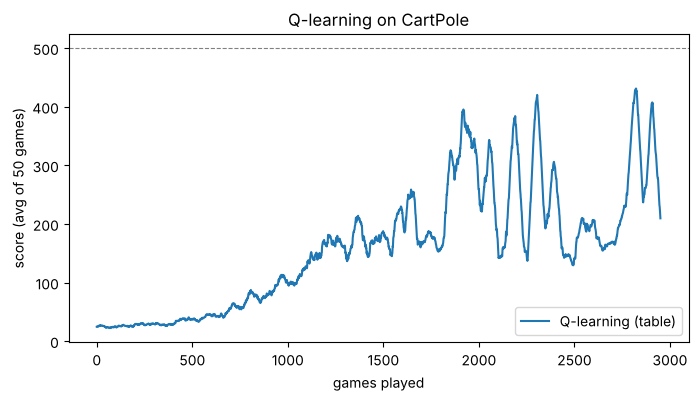

In [19]:
import matplotlib.pyplot as plt

def moving_average(x, w=50):
    # average of every 50 consecutive games, so the line is readable
    x = np.array(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode="valid")

plt.figure(figsize=(8, 4))
plt.plot(moving_average(q_scores), label="Q-learning (table)")
plt.xlabel("games played")
plt.ylabel("score (avg of 50 games)")
plt.title("Q-learning on CartPole")
plt.axhline(500, color="gray", linestyle="--", linewidth=0.8)
plt.legend()
plt.show()

# Part 7: Actor-critic on the dummy game (the idea behind A2C)

Q-learning learns *how good each action is* and then picks the best. **Actor-critic** learns two separate things:

- **Actor** = the policy itself. For each state it holds one **preference** per action, and a function called **softmax** turns preferences into probabilities. You then roll dice with those probabilities to choose. (So the actor sometimes picks the less-favored action, which is its built-in exploring; no epsilon needed.)
- **Critic** = one number per state: "from this state, about how many points do I expect to collect?" It judges situations. It never picks actions.

### Softmax, with examples

Softmax turns any list of numbers into probabilities that add to 1. Bigger preference means more likely, but never 100% certain.

In [20]:
def softmax(prefs):
    e = np.exp(prefs - np.max(prefs))
    return e / e.sum()

for prefs in [[0.0, 0.0], [1.0, 0.0], [3.0, 0.0], [0.0, 3.0]]:
    p = softmax(np.array(prefs))
    print(f"preferences [left, right] = {prefs}  ->  probabilities {np.round(p, 3)}")

preferences [left, right] = [0.0, 0.0]  ->  probabilities [0.5 0.5]
preferences [left, right] = [1.0, 0.0]  ->  probabilities [0.731 0.269]
preferences [left, right] = [3.0, 0.0]  ->  probabilities [0.953 0.047]
preferences [left, right] = [0.0, 3.0]  ->  probabilities [0.047 0.953]


### Advantage: "better or worse than usual?"

After each step:
1. The critic had predicted `V[state]` points from where you were.
2. What actually happened is worth `reward + gamma * V[next_state]` (the point you just got plus the critic's estimate of the future). That's the **target**, same idea as in Q-learning.
3. **advantage = target - V[state]**. Positive means "that went better than the critic expected." Negative means worse.

Then two updates:
- **Critic update:** move `V[state]` a fraction toward the target. (Same "fraction of the way" as Q-learning.)
- **Actor update:** if advantage is positive, **raise the preference** for the action you took (and lower the other); if negative, lower it. The size of the nudge is proportional to the advantage.

Here is one update with pretend numbers, so you can see every piece:

In [21]:
gamma = 0.9
alpha_critic = 0.2
alpha_actor = 0.5

# PRETEND numbers
H_A = np.array([0.0, 0.0])      # actor's preferences in state A: [left, right]
V_A = 20.0                      # critic's guess for state A
V_B = 22.0                      # critic's guess for next state B
action = 1                      # we pushed right
reward = 1

probs = softmax(H_A)
target = reward + gamma * V_B
advantage = target - V_A
print(f"probabilities from actor in A        = {np.round(probs, 3)}")
print(f"target    = reward + gamma*V_B       = {reward} + {gamma}*{V_B} = {target}")
print(f"advantage = target - V_A             = {target} - {V_A} = {advantage:.2f}   (positive: better than expected)")
print()

# critic update
new_V_A = V_A + alpha_critic * advantage
print(f"critic: V_A {V_A} -> {new_V_A:.3f}   (moved {alpha_critic} of the way toward the target)")

# actor update
chosen_one_hot = np.array([0.0, 1.0])               # marks which action we took
grad = chosen_one_hot - probs                       # = [-0.5, +0.5]
new_H_A = H_A + alpha_actor * advantage * grad
print(f"actor:  gradient direction = one-hot(action) - probs = {chosen_one_hot} - {np.round(probs,2)} = {grad}")
print(f"        preferences {H_A} -> {np.round(new_H_A, 3)}")
print(f"        probabilities {np.round(softmax(H_A), 3)} -> {np.round(softmax(new_H_A), 3)}   (pushing right is now more likely)")

probabilities from actor in A        = [0.5 0.5]
target    = reward + gamma*V_B       = 1 + 0.9*22.0 = 20.8
advantage = target - V_A             = 20.8 - 20.0 = 0.80   (positive: better than expected)

critic: V_A 20.0 -> 20.160   (moved 0.2 of the way toward the target)
actor:  gradient direction = one-hot(action) - probs = [0. 1.] - [0.5 0.5] = [-0.5  0.5]
        preferences [0. 0.] -> [-0.2  0.2]
        probabilities [0.5 0.5] -> [0.401 0.599]   (pushing right is now more likely)


**Why `one-hot(action) - probs`?** It says: raise the preference of the action you took by "1 minus its probability," and lower each other action by that action's probability. So an action you already choose 99% of the time barely moves, while a rare action that turned out well moves a lot. (This formula comes out of calculus on the log of the probability. We're not deriving it here; what matters is the behavior shown above.)

### Training on the dummy game
Same game, same 3 states. The actor table `H` and critic table `V` both start at zero.

In [22]:
def train_ac_dummy(num_games, alpha_actor, alpha_critic, gamma):
    H = {s: np.zeros(2) for s in [-2, 0, 2]}        # actor: preferences per state
    V = {s: 0.0 for s in [-2, 0, 2]}                # critic: value per state

    for g in range(num_games):
        game = DummyGame()
        state = game.reset()
        while True:
            probs = softmax(H[state])
            action = int(np.random.choice(2, p=probs))      # roll dice with the actor's probabilities

            next_state, reward, terminated, truncated = game.step(action)

            future = 0.0 if terminated else V[next_state]
            target = reward + gamma * future
            advantage = target - V[state]

            V[state] = V[state] + alpha_critic * advantage          # critic update

            grad = -probs.copy()
            grad[action] += 1.0                                      # one-hot(action) - probs
            H[state] = H[state] + alpha_actor * advantage * grad     # actor update

            state = next_state
            if terminated or truncated:
                break
    return H, V

np.random.seed(2)
H, V = train_ac_dummy(num_games=3000, alpha_actor=0.1, alpha_critic=0.2, gamma=0.9)

for s in [-2, 0, 2]:
    p = softmax(H[s])
    print(f"state {s:+d}: critic V = {V[s]:5.2f} | actor probabilities  left {p[0]:.2f}   right {p[1]:.2f}")

state -2: critic V =  7.89 | actor probabilities  left 0.10   right 0.90
state +0: critic V = 10.00 | actor probabilities  left 0.00   right 1.00
state +2: critic V = 10.00 | actor probabilities  left 1.00   right 0.00


In [23]:
def actor_policy(state):
    p = softmax(H[state])
    return int(np.random.choice(2, p=p))

ac_scores = [play_one_game(actor_policy) for _ in range(1000)]
print("coin flip      :", sum(coin_scores) / 1000)
print("hand-made rule :", sum(rule_scores) / 1000)
print("Q-table        :", sum(learned) / 1000)
print("actor-critic   :", sum(ac_scores) / 1000)

coin flip      : 8.171
hand-made rule : 50.0
Q-table        : 50.0
actor-critic   : 50.0


**What to notice:** at tilt +2 the actor now assigns most of its probability to *left*, and at tilt -2 to *right*, same conclusion as the Q-table, reached a different way. The critic's V numbers top out around 10. That's not a coincidence: with +1 per tick and `gamma = 0.9`, the most any state can be worth is 1 + 0.9 + 0.81 + ... = 1 / (1 - 0.9) = 10.

**Where this goes in real CartPole:** identical code, with `to_bucket(obs)` as the state. That's the next part.

# Part 8: Actor-critic on real CartPole

Same loop as Part 7. Changes: state = `to_bucket(obs)`, tables are numpy arrays, `gamma = 0.99`.

In [24]:
def train_ac_cartpole(episodes, alpha_actor=0.1, alpha_critic=0.2, gamma=0.99):
    H = np.zeros(tuple(bucket_counts) + (2,))       # actor: 2 preferences per state
    V = np.zeros(tuple(bucket_counts))              # critic: 1 value per state
    scores = []
    for ep in range(episodes):
        obs, info = env.reset()
        state = to_bucket(obs)
        total = 0
        while True:
            probs = softmax(H[state])
            action = int(np.random.choice(2, p=probs))

            obs, reward, terminated, truncated, info = env.step(action)
            next_state = to_bucket(obs)

            future = 0.0 if terminated else V[next_state]
            target = reward + gamma * future
            advantage = target - V[state]

            V[state] += alpha_critic * advantage            # critic update

            grad = -probs.copy()
            grad[action] += 1.0
            H[state] += alpha_actor * advantage * grad      # actor update

            state = next_state
            total = total + reward
            if terminated or truncated:
                break

        scores.append(total)
        if (ep + 1) % 500 == 0:
            print(f"games {ep+1-499:5d}-{ep+1:5d}: average score {np.mean(scores[-500:]):6.1f}")
    return H, V, scores

np.random.seed(0)
H_cart, V_cart, ac_cart_scores = train_ac_cartpole(3000)

games     1-  500: average score  178.3


games   501- 1000: average score  199.8


games  1001- 1500: average score  199.3


games  1501- 2000: average score  202.2


games  2001- 2500: average score  200.0


games  2501- 3000: average score  201.3


In [25]:
def ac_cartpole_policy(obs):
    p = softmax(H_cart[to_bucket(obs)])
    return int(np.random.choice(2, p=p))

def ac_cartpole_greedy_policy(obs):
    return int(np.argmax(H_cart[to_bucket(obs)]))

avg, best = evaluate_cartpole(ac_cartpole_policy, 100)
print(f"actor-critic, rolling dice : average {avg:.1f}, best {best:.0f}")
avg, best = evaluate_cartpole(ac_cartpole_greedy_policy, 100)
print(f"actor-critic, always the top-preference action: average {avg:.1f}, best {best:.0f}")

actor-critic, rolling dice : average 199.3, best 300


actor-critic, always the top-preference action: average 205.2, best 292


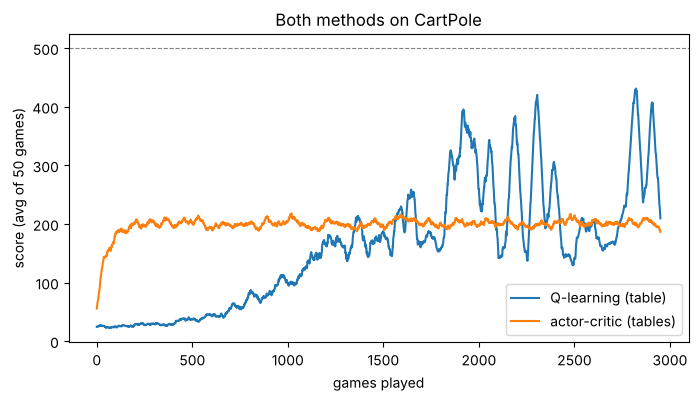

In [26]:
plt.figure(figsize=(8, 4))
plt.plot(moving_average(q_scores), label="Q-learning (table)")
plt.plot(moving_average(ac_cart_scores), label="actor-critic (tables)")
plt.xlabel("games played")
plt.ylabel("score (avg of 50 games)")
plt.title("Both methods on CartPole")
plt.axhline(500, color="gray", linestyle="--", linewidth=0.8)
plt.legend()
plt.show()

**How to read this:** both improve far past the random-play score (~22), which means they are really learning from the +1-per-tick signal alone. They differ in shape: actor-critic jumps up within the first few hundred games (it adjusts its policy directly), while Q-learning is slow at first (its early games are mostly random exploring) and then climbs.

Also look at where actor-critic stops: it levels off around 200 and stays there, while the Q-learning line in the same plot goes higher during training (though the final Q-table's score on the 100 test games above was lower than its training average, so don't read too much into that gap: one table can wobble, and I only ran each method once). I have not tested *why* actor-critic stalls. One plausible cause is that the coarse buckets hide information the actor needs (for example the slow drift of the cart toward the edge), but treat that as a guess, not a result. It's also a reason people move to neural networks, which don't need buckets at all.

**Important honesty about what "A2C" means.** What we built is the real *logic* of A2C: an actor, a critic, an advantage, and the two updates. The actual algorithm named **A2C** (Advantage Actor-Critic) differs in two practical ways:

1. The tables are replaced by **neural networks**, so it can use the 4 raw decimals directly with no bucketing (Part 9 shows what that means).
2. It collects a short run of steps (often from several games played in parallel) before each update, and averages the updates over that batch, which makes learning steadier.

If you can follow Parts 7 and 8, then every line of an A2C file is one of: "run the actor," "run the critic," "compute the advantage," "nudge the critic," "nudge the actor."

# Part 9: Where neural networks come in

The tables have a weakness: we had to chop the numbers into buckets, and the table knows nothing about a bucket it hasn't visited. Two nearby states that land in different buckets are completely unrelated rows.

A **neural network** replaces "look up a row" with "compute from the raw numbers." Let's start with the very simplest version, a single line of arithmetic: multiply each input by its own **weight**, add them up, add a **bias**:

`output = w1*x1 + w2*x2 + w3*x3 + w4*x4 + bias`

The weights are the adjustable numbers; "learning" means adjusting them. Here with made-up numbers, with the arithmetic shown:

In [27]:
weights = np.array([0.5, -0.2, 1.0, 0.3])
bias = 0.0
x = np.array([0.02, -0.4, 0.05, 0.6])          # pretend CartPole observation

parts = weights * x
print("weight * input, one pair at a time:", np.round(parts, 4))
print("add them up + bias =", round(float(parts.sum() + bias), 4))
print("same thing with numpy's @ operator  =", round(float(weights @ x + bias), 4))

weight * input, one pair at a time: [0.01 0.08 0.05 0.18]
add them up + bias = 0.32
same thing with numpy's @ operator  = 0.32


### "Updating" a network = the same fraction-of-the-way idea

In Q-learning we moved a table entry a fraction toward a target. For the network we do the same to its **output**, but since the output depends on all the weights, we nudge every weight a little. Each weight is nudged by `alpha * error * its input`: a weight whose input was big contributed more to the error, so it gets nudged more.

Below we repeatedly tell the network "for this input, the answer should be 1.0" and watch the output move.

In [28]:
weights = np.array([0.5, -0.2, 1.0, 0.3])
bias = 0.0
x = np.array([0.02, -0.4, 0.05, 0.6])
target = 1.0
alpha = 0.5

print(f"before any update: output = {weights @ x + bias:.4f}   (target {target})")
for step in range(1, 31):
    output = weights @ x + bias
    error = target - output
    weights = weights + alpha * error * x           # nudge each weight by (error * its input)
    bias = bias + alpha * error
    if step in (1, 2, 3, 5, 10, 20, 30):
        print(f"after {step:2d} updates: output = {weights @ x + bias:.4f}")

before any update: output = 0.3200   (target 1.0)
after  1 updates: output = 0.8378
after  2 updates: output = 0.9613
after  3 updates: output = 0.9908
after  5 updates: output = 0.9995
after 10 updates: output = 1.0000
after 20 updates: output = 1.0000
after 30 updates: output = 1.0000


### The big difference from a table: it generalizes

We only ever trained on one input. Now ask it about a *similar* input and a *very different* input. A table would say "never seen it, no idea" for both (a new row of zeros). The network gives an answer for any input:

In [29]:
similar = np.array([0.03, -0.35, 0.06, 0.55])
different = np.array([-0.5, 0.9, -0.15, -1.5])

print(f"trained input      -> {weights @ x + bias:.4f}")
print(f"similar input      -> {weights @ similar + bias:.4f}")
print(f"very different one -> {weights @ different + bias:.4f}")

trained input      -> 1.0000
similar input      -> 0.9680
very different one -> -1.1539


**Mapping the whole notebook onto networks:**

| In the table version | In the network version |
|---|---|
| `Q[state]` returns 2 scores | a network takes the 4 raw numbers and outputs 2 scores |
| actor `H[state]` returns 2 preferences, then `softmax` | an "actor network" outputs 2 preferences, then `softmax` |
| critic `V[state]` returns 1 number | a "critic network" outputs 1 number |
| update = move a table entry a fraction toward the target | update = nudge **all the weights** so the output moves toward the target |

Real networks stack several of these weighted-sum steps with a bend between them (so they can represent curves, not just straight lines). A library such as PyTorch works out the weight nudges for you, but the logic of what to move toward is exactly what you computed in Parts 3 and 7.

# Part 10: Glossary (plain words, and where we saw it)

| Word | What it means here | Where |
|---|---|---|
| **state** | The numbers describing the situation right now | Part 1 |
| **action** | The choice you make each tick (0 = left, 1 = right) | Part 1 |
| **reward** | Points for the step you just took (+1 per tick) | Part 1 |
| **terminated / truncated** | Game over because you failed / because time ran out | Part 1 |
| **MDP** (Markov Decision Process) | The name for "a game with states, actions, rewards, where the next state depends only on the current state and your action." Everything in Part 1 *is* one | Part 1 |
| **policy** | A function: state in, action out | Part 2 |
| **Q value** | Estimated total future points for taking an action in a state | Part 3 |
| **target** | A better guess for a number, built from the reward you just saw plus an estimate of what follows | Parts 3, 7 |
| **learning rate (alpha)** | What fraction of the way to move toward the target | Part 3 |
| **discount (gamma)** | How much a point one step later counts vs a point now | Part 3 |
| **epsilon / exploring** | Chance of ignoring the table and trying a random action | Part 3 |
| **bucketing / discretizing** | Turning a decimal into "which interval is it in" so a table can hold it | Part 5 |
| **actor** | The policy: holds preferences, turned into probabilities by softmax | Part 7 |
| **critic** | Estimates how good a state is (never picks actions) | Part 7 |
| **advantage** | `target - critic's guess`. Positive = better than expected | Part 7 |
| **softmax** | Turns preferences into probabilities that add to 1 | Part 7 |
| **weights** | The adjustable numbers inside a network | Part 9 |
| **A2C** | Actor + critic + advantage, with networks instead of tables, updated on small batches of steps | Parts 7-9 |

### What would come next
The natural next piece is the real A2C: the same actor, critic and advantage from Part 7, but with the tables replaced by small neural networks that read the 4 raw CartPole numbers, built one piece at a time the same way.